# Evalúa una búsqueda asistida por surrogate

**Pregunta:** ¿Cómo cambia el análisis «Evalúa una búsqueda asistida por surrogate» al ejecutar el mismo mineral de autoría propia con tratamientos controlados?

Nivel: 3. Requisitos previos: Niveles 1 y 2 de este tema y nivel 3 de aprendizaje. Tiempo de lectura: 26 minutos.

## Objetivos

Compara la búsqueda con y sin filtro surrogate en el mismo registro del benchmark e interpreta cómo el peso del objetivo cambia el intercambio entre recuperación y energía.

## Preparación

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

El pipeline OreFlow se importa desde `data-pipeline/`; este notebook nunca instala paquetes.

Configura las importaciones y registra versiones. Este paso hace reproducible la ejecución del método.

In [1]:
# Importa herramientas de análisis y registra sus versiones exactas.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resuelve el pipeline local desde la estructura relativa del repositorio.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Datos

Responsable: autores de OreFlow; `data/derived/benchmark.json` guarda variantes evaluadas del optimizador para doce casos de autoría propia, licencia MIT del proyecto. Repositorio: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Método

Un marco de gestión con surrogate puede ordenar evaluaciones propuestas, pero OreFlow evalúa candidatos con el motor de procesos. El guard autoencoder y el límite de intervalo GP filtran propuestas; el sondeo de búsqueda sigue siendo autoritativo. La trayectoria de pesos informa el intercambio condicional entre metal recuperado y energía específica. Se comparan conteos medidos y trayectorias del bake; no se afirma un algoritmo nuevo.

## Comparación

La búsqueda generalizada por patrones y las barreras progresivas son métodos establecidos (Torczon, 1997; Audet y Dennis, 2009). La gestión con surrogate puede guiar evaluaciones costosas (Booker et al., 1999). La evidencia OreFlow es específica al caso: búsqueda filtrada y sin filtrar alcanzan el mismo óptimo registrado en esta fila, y los conteos muestran si se ahorró trabajo. No es una prueba para todos los casos ni un óptimo económico.

Carga la comparación del benchmark con y sin filtro surrogate e informa qué evaluó realmente el motor.

In [2]:
# Carga la comparación del benchmark con y sin filtro surrogate e informa qué evaluó realmente el
# motor.
repo = Path("../../../").resolve()
benchmark = json.loads((repo / "data/derived/benchmark.json").read_text(encoding="utf-8"))
row = benchmark["optimization"]["copper_porphyry_soft"]["nominal"]
comparison = pd.DataFrame(
    [
        {"search": "surrogate screened", "evaluations": row["evaluations"]},
        {"search": "unscreened", "evaluations": row["evaluations_without_screen"]},
    ]
)
print("same optimum:", row["same_optimum_without_screen"])
print("screen proposals:", row["proposed"], "| improved incumbents:", row["improved"])
print("engine evaluations saved:", row["evaluations_without_screen"] - row["evaluations"])
display(comparison)


same optimum: True
screen proposals: 72 | improved incumbents: 18
engine evaluations saved: -43


,search,evaluations
0,surrogate screened,309
1,unscreened,266


Grafica la trayectoria de ponderaciones registrada. Reducir el peso del metal cambia el objetivo; no modifica el modelo del mineral ni de la planta.

,weight,status,recovered_tph,energy_kwh_t
0,0.75,optimal,5.013899,10.213139
1,0.50,optimal,4.198802,7.349207
2,0.25,optimal,3.969572,7.102007


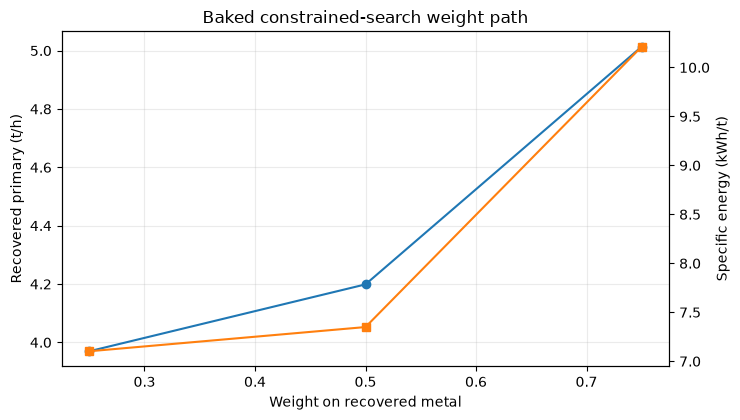

In [3]:
# Grafica la trayectoria de ponderaciones registrada.
path = pd.DataFrame(row["path"])
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(path["weight"], path["recovered_tph"], marker="o", label="recovered primary")
ax.set(
    xlabel="Weight on recovered metal",
    ylabel="Recovered primary (t/h)",
    title="Baked constrained-search weight path",
)
ax.grid(True, alpha=0.25)
ax2 = ax.twinx()
ax2.plot(
    path["weight"], path["energy_kwh_t"], marker="s", color="tab:orange", label="specific energy"
)
ax2.set_ylabel("Specific energy (kWh/t)")
fig.tight_layout()
display(path)


Lee el ahorro de evaluaciones junto al error absoluto de recuperación del surrogate; ninguna magnitud mide desempeño en planta.

La figura 12 del nivel 3 sobre 04 optimization resume circuitos OreFlow resueltos en los ajustes indicados. La línea solo guía la comparación; no es una ley de respuesta ajustada ni una banda de confianza. Revisa ejes, contrato y salidas pareadas para responder la pregunta operativa.

In [4]:
# Lee el ahorro de evaluaciones junto al error absoluto de recuperación del surrogate; ninguna
# magnitud mide desempeño en planta.
print("screened evaluations:", row["evaluations"])
print("unscreened evaluations:", row["evaluations_without_screen"])
print("surrogate absolute error (percentage points):", round(row["surrogate_abs_error_pp"], 4))
print("same optimum:", row["same_optimum_without_screen"])
print("limits: authored simulator cases only; no field calibration or economic objective")


screened evaluations: 309
unscreened evaluations: 266
surrogate absolute error (percentage points): 0.4126
same optimum: True
limits: authored simulator cases only; no field calibration or economic objective


Para el caso de nivel 3 sobre 04 optimization, solo cambia la alimentación fresca con 0.8 veces el tratamiento nominal. Esta comparación de nivel 3 sobre 04 optimization, con 0.8 veces el tratamiento nominal, usa recuperación, P80 y energía para evaluar las restricciones declaradas.

In [5]:
# Recalcula el caso de autoría propia con un tratamiento controlado.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_1 = 0.8
point_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_1)
response_1 = simulate(case.ore, case.plant, point_1)
print('tratamiento (t/h):', round(point_1.throughput_tph, 2))
print('recuperación (%):', round(response_1.metrics['recovery_pct'], 3))
print('P80 de producto (µm):', round(response_1.metrics['p80_um'], 2))

tratamiento (t/h): 576.0
recuperación (%): 93.788
P80 de producto (µm): 150.0


Para el caso de nivel 3 sobre 04 optimization, solo cambia la alimentación fresca con 0.9 veces el tratamiento nominal. Esta comparación de nivel 3 sobre 04 optimization, con 0.9 veces el tratamiento nominal, usa recuperación, P80 y energía para evaluar las restricciones declaradas.

In [6]:
# Recalcula el caso de autoría propia con un tratamiento controlado.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_2 = 0.9
point_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_2)
response_2 = simulate(case.ore, case.plant, point_2)
print('tratamiento (t/h):', round(point_2.throughput_tph, 2))
print('recuperación (%):', round(response_2.metrics['recovery_pct'], 3))
print('P80 de producto (µm):', round(response_2.metrics['p80_um'], 2))

tratamiento (t/h): 648.0
recuperación (%): 92.996
P80 de producto (µm): 150.0


Para el caso de nivel 3 sobre 04 optimization, solo cambia la alimentación fresca con 1.0 veces el tratamiento nominal. Esta comparación de nivel 3 sobre 04 optimization, con 1.0 veces el tratamiento nominal, usa recuperación, P80 y energía para evaluar las restricciones declaradas.

In [7]:
# Recalcula el caso de autoría propia con un tratamiento controlado.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_3 = 1.0
point_3 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_3)
response_3 = simulate(case.ore, case.plant, point_3)
print('tratamiento (t/h):', round(point_3.throughput_tph, 2))
print('recuperación (%):', round(response_3.metrics['recovery_pct'], 3))
print('P80 de producto (µm):', round(response_3.metrics['p80_um'], 2))

tratamiento (t/h): 720.0
recuperación (%): 92.213
P80 de producto (µm): 150.0


Para el caso de nivel 3 sobre 04 optimization, solo cambia la alimentación fresca con 1.1 veces el tratamiento nominal. Esta comparación de nivel 3 sobre 04 optimization, con 1.1 veces el tratamiento nominal, usa recuperación, P80 y energía para evaluar las restricciones declaradas.

In [8]:
# Recalcula el caso de autoría propia con un tratamiento controlado.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_4 = 1.1
point_4 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_4)
response_4 = simulate(case.ore, case.plant, point_4)
print('tratamiento (t/h):', round(point_4.throughput_tph, 2))
print('recuperación (%):', round(response_4.metrics['recovery_pct'], 3))
print('P80 de producto (µm):', round(response_4.metrics['p80_um'], 2))

tratamiento (t/h): 792.0
recuperación (%): 91.437
P80 de producto (µm): 150.0


Para el caso de nivel 3 sobre 04 optimization, solo cambia la alimentación fresca con 1.2 veces el tratamiento nominal. Esta comparación de nivel 3 sobre 04 optimization, con 1.2 veces el tratamiento nominal, usa recuperación, P80 y energía para evaluar las restricciones declaradas.

In [9]:
# Recalcula el caso de autoría propia con un tratamiento controlado.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_5 = 1.2
point_5 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_5)
response_5 = simulate(case.ore, case.plant, point_5)
print('tratamiento (t/h):', round(point_5.throughput_tph, 2))
print('recuperación (%):', round(response_5.metrics['recovery_pct'], 3))
print('P80 de producto (µm):', round(response_5.metrics['p80_um'], 2))

tratamiento (t/h): 864.0
recuperación (%): 88.442
P80 de producto (µm): 165.93


En el nivel 3 de 04 optimization, los paneles usan los mismos ajustes y 5 puntos resueltos por el modelo, no observaciones de planta. En el nivel 3, la tendencia de 04 optimization es la respuesta local de un caso de autoría propia y puede cambiar cerca de límites de potencia o ley; no estima un efecto causal en planta.

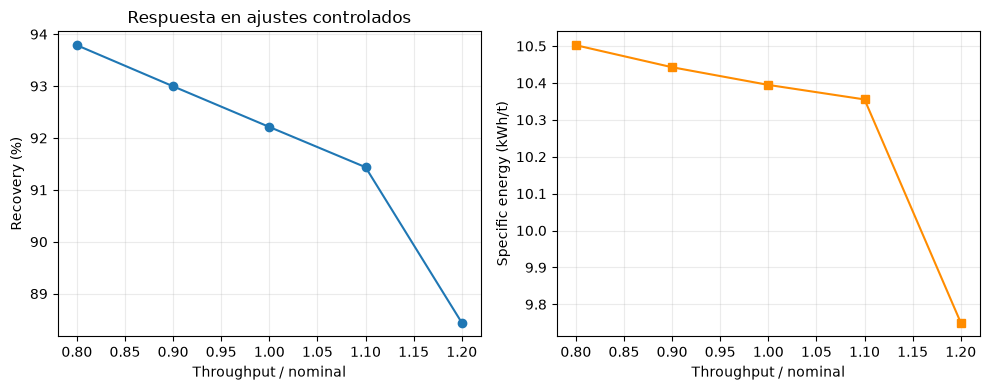

In [10]:
# Compare recovery and specific energy from the executed circuit runs.
import matplotlib.pyplot as plt
factors = [0.8, 0.9, 1.0, 1.1, 1.2]
runs = [response_1, response_2, response_3, response_4, response_5]
recovery = [run.metrics['recovery_pct'] for run in runs]
energy = [run.metrics['specific_energy_total_kwh_t'] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, recovery, marker='o')
axes[0].set(xlabel='Throughput / nominal', ylabel='Recovery (%)', title='Respuesta en ajustes controlados')
axes[1].plot(factors, energy, marker='s', color='darkorange')
axes[1].set(xlabel='Throughput / nominal', ylabel='Specific energy (kWh/t)')
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()

En el análisis de nivel 3 sobre 04 optimization, lee esta respuesta de tamaño junto a los paneles de recuperación y energía, no como sustituto. En el nivel 3, un objetivo de molienda constante en este caso de 04 optimization puede mantener P80 casi sin cambio mientras potencia, recirculación y residencia alteran otras salidas. Para 04 optimization en nivel 3, conserva las alertas del modelo y la auditoría de balance junto con el resultado.

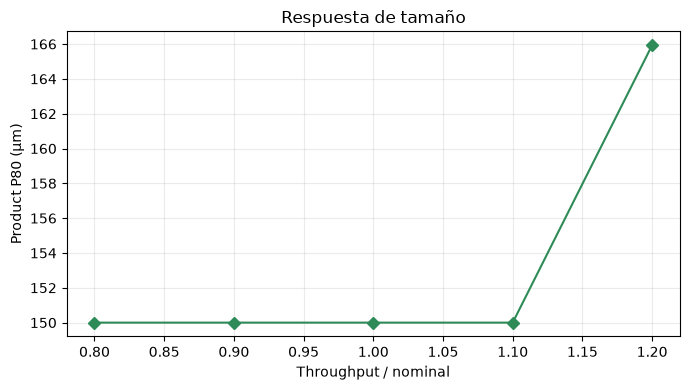

In [11]:
# # Muestra el tamaño de producto aparte: se mide en micrómetros, no en energía o recuperación.
fig, ax = plt.subplots(figsize=(7, 4))
sizes = [run.metrics['p80_um'] for run in runs]
ax.plot(factors, sizes, marker='D', color='seagreen')
ax.set(xlabel='Throughput / nominal', ylabel='Product P80 (µm)', title='Respuesta de tamaño')
ax.grid(True, alpha=0.25)
fig.tight_layout()

En el nivel 3 de 04 optimization, la interpretación 1 es que un resultado de optimización depende del objetivo, la región factible, el punto inicial y la condición de detención. En el nivel 3 de 04 optimization, la interpretación 2 es que la búsqueda de OreFlow evalúa un circuito de procesamiento mineral y usa una barrera progresiva para acercarse a la factibilidad. En el nivel 3 de 04 optimization, la interpretación 3 es que sus variables de decisión no son intercambiables porque tamaño de molienda, dosis de colector y velocidad del gas afectan restricciones distintas. En el nivel 3 de 04 optimization, la interpretación 4 es que una puntuación escalar puede ocultar compromisos, por lo que se deben inspeccionar conjuntamente metal recuperado, energía específica, ley de concentrado, agua y holgura de restricciones. En el nivel 3 de 04 optimization, la interpretación 5 es que el benchmark comprometido compara corridas con y sin filtro en casos de autoría emparejados y cuenta evaluaciones exactas del motor. En el nivel 3 de 04 optimization, la interpretación 6 es que un surrogate puede priorizar candidatos, pero solo el motor de proceso determina las salidas físicas. En el nivel 3 de 04 optimization, la interpretación 7 es que reevalúa cada óptimo informado con ese motor, conserva corridas rechazadas e infactibles e informa el motivo de detención. En el nivel 3 de 04 optimization, la interpretación 8 es que la comparación permite inspeccionar el método; una decisión de planta aún requiere una campaña calibrada de forma independiente y un modelo de costos aprobado por operaciones. En el nivel 3 de 04 optimization, la interpretación 9 es que un estudio de despliegue requiere límites de planta, datos validados de ensayos y sensores, un modelo de costos aprobado por operaciones y una campaña reservada. En el nivel 3 de 04 optimization, la interpretación 10 es que la sensibilidad a los pesos debe mostrarse como compromiso de Pareto y no reducirse a un único ajuste supuestamente óptimo para todos.

Ejecuta una búsqueda de referencia nueva y sin filtro con el mismo caso y contrato. Sus evaluaciones de proceso son más costosas que leer el registro guardado de varios casos, pero muestran el método directamente.

In [12]:
# Ejecuta la búsqueda del producto sin filtro en el caso de autoría propia.
from pipeline.io.contract import build_contract
from pipeline.methods.optimization import optimize
search_reference = optimize(case, case.nominal, build_contract(), weight=0.5, path=False)
print('método de búsqueda:', search_reference['method'])
print('evaluaciones de búsqueda:', search_reference['evaluations'])

método de búsqueda: gps-progressive-barrier
evaluaciones de búsqueda: 258


## Resultados

**Respuesta:** En esta lección de nivel 3 sobre 04 optimization, el circuito ejecutado informa una recuperación de 93.788 por ciento para «Evalúa una búsqueda asistida por surrogate» en el primer tratamiento controlado.

El conteo de evaluaciones mide el trabajo computacional de una búsqueda horneada. La trayectoria de pesos muestra el intercambio recuperación-energía bajo restricciones del motor. Ni el error del surrogate ni coincidir en el extremo predicen la respuesta de una planta real.

## Resumen

Comparaste el ordenamiento asistido por surrogate con la búsqueda evaluada por el motor e inspeccionaste una trayectoria de objetivo comprometida. El alcance es acotado a los escenarios de autoría propia, sin validación en planta.

## Referencias

- https://doi.org/10.1137/S1052623493250780
- https://doi.org/10.1137/070692662
- https://doi.org/10.1007/BF01197708
- https://doi.org/10.1017/CBO9780511790423